In [1]:
import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [3]:
file_location = os.path.join('C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs', '*.txt')
filenames = glob.glob(file_location)

### Setting to adjust umap density
#### Original values: 
* `init_dt = 0.01`
* `dt = 0.2`
* `window = 2`
* `time_step = 1`

#### umap params
* `neighbs = 50`
* `min_d = 0.05`


### Filenaming convention
Filename will incorporate parameter values in order above (not including umap parameters).

In [21]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
"""
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 5                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 150
min_d = 0.05

#reducer save name
r_name = f'\\reducer_04_29_{init_dt}_{dt}_{window}_{time_step}.sav'

In [22]:
filenames

['C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_1_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_2_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\dmso_long_4_29_3_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_4_29_1_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_4_29_2_1.txt',
 'C:\\Users\\olesk\\OneDrive\\Documents\\stoch_runs\\erl_long_4_29_3_1.txt']

In [6]:
#Load and resample time based on umap window
time_tmp = pd.read_csv('t_4-9_3_3.txt', sep=",", header=None)
time_tmp = time_tmp.T
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
    

In [23]:
#create window and total protein arrays
win_len = int(window/dt)
all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
all_time_tmp = np.empty((0,win_len))
all_time_at_tmp = np.empty((0,1))
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

for f in filenames:
    prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
        
    all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
    all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
    all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)


In [24]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=2,
        low_memory=True        
        ).fit(all_prot_tmp)

embedding_all_prot = reducer.transform(all_prot_tmp)

In [15]:
win_len

40

In [39]:
joblib.dump(reducer, str(SAVEDIR) + r_name)

['C:\\Users\\olesk\\ECM_mod_output\\UMAP\\reducer_04_10_0.01_0.1_4_0.2.sav']

In [9]:
import matplotlib.pyplot as plt

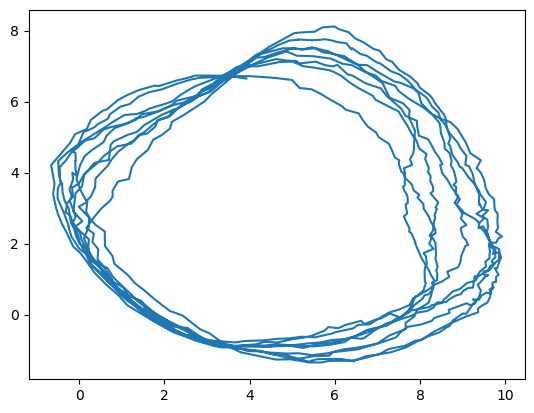

In [14]:
fig = plt.figure()
plt.plot(embedding_all_prot[0:1000,0], embedding_all_prot[0:1000,1])

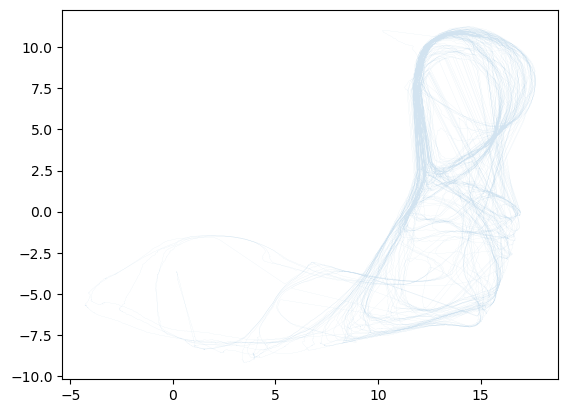

In [19]:
fig = plt.figure()
plt.plot(embedding_all_prot[24981*1:24981*2,0], embedding_all_prot[24981*1:24981*2,1], lw=0.1, alpha=0.2)

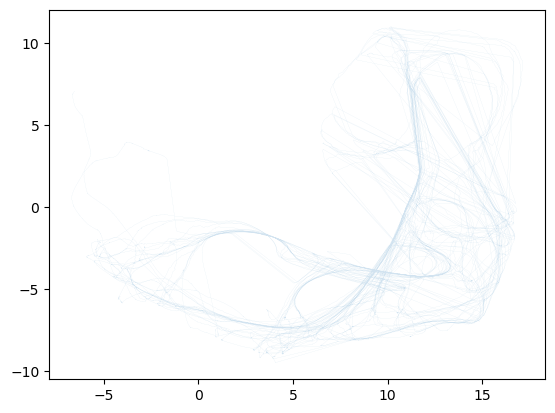

In [20]:
fig = plt.figure()
plt.plot(embedding_all_prot[24981*4:24981*5,0], embedding_all_prot[24981*4:24981*5,1], lw=0.1, alpha=0.2)

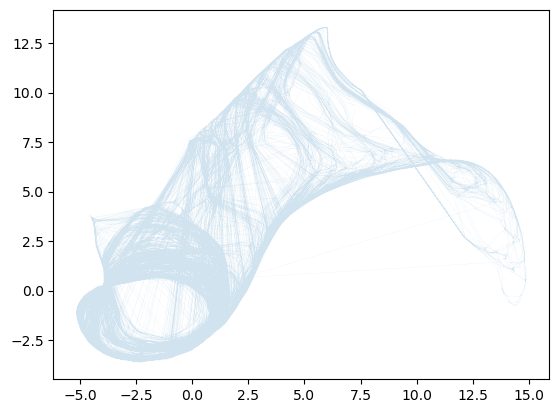

In [25]:
fig = plt.figure()
plt.plot(embedding_all_prot[:,0], embedding_all_prot[:,1], lw=0.1, alpha=0.2)

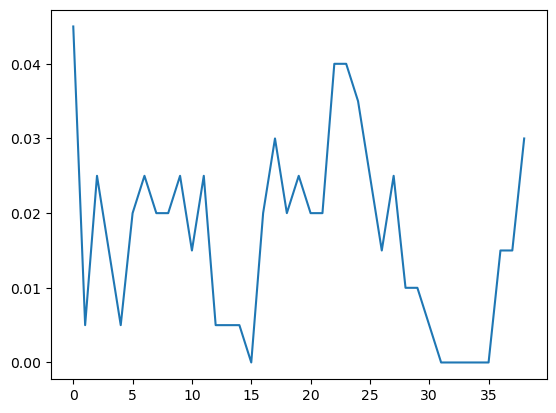

In [18]:
fig = plt.figure()
plt.plot(all_prot_tmp[0,80:119])